# Billionaires: Compare industries

## 1 · Import libraries and load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


%matplotlib inline

In [3]:
billionaires = pd.read_csv('H:\\Training for Interview - PART INC\\Github\\MasterClass-FinTech-01\\session_1\\3.billionaires\\Billionaire.csv')
print('Rows and columns:', billionaires.shape)

Rows and columns: (2755, 7)


In [4]:
billionaires.head()

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology


In [19]:
billionaires.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2755 entries, 0 to 2754
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      2755 non-null   object 
 1   NetWorth  2755 non-null   object 
 2   Country   2755 non-null   object 
 3   Source    2755 non-null   object 
 4   Rank      2755 non-null   int64  
 5   Age       2676 non-null   float64
 6   Industry  2755 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 150.8+ KB


In [20]:
print('Missing values:')
billionaires.isna().sum()

Missing values:


Name         0
NetWorth     0
Country      0
Source       0
Rank         0
Age         79
Industry     0
dtype: int64

Industry is the column I need - check it's clean (no NaN, no stray spaces / duplicate spellings)

In [21]:
print("unique industries:", billionaires["Industry"].nunique())
print("unique after strip():", billionaires["Industry"].str.strip().nunique())

unique industries: 18
unique after strip(): 18


## 2. Count billionaires per industry

SQL equivalent:
SELECT Industry, COUNT(*) AS n FROM billionaires
GROUP BY Industry ORDER BY n DESC;

In [22]:
industry_counts = billionaires.groupby("Industry").size().sort_values(ascending=False)
industry_counts.to_frame("billionaires")

,billionaires
Industry,
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100


## 3. Keep the top 10 and group the rest as `Other`

In [23]:
top10 = industry_counts.iloc[:10]
other = industry_counts.iloc[10:].sum()

final_counts = pd.concat([top10, pd.Series({"Other": other})])
final_counts.to_frame("n_billionaires")

,n_billionaires
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100
Media & Entertainment,95


sanity check: nothing lost when grouping

In [26]:
print("sum of grouped counts:", final_counts.sum())
print("total rows:", len(billionaires))
assert final_counts.sum() == len(billionaires)

print("industries in Other:", len(industry_counts) - 10)

sum of grouped counts: 2755
total rows: 2755
industries in Other: 8


I keep `Other` as the last category on purpose. If I re-sorted, `Other` (377) would jump to first place because it's bigger than the largest single industry (371), and the ranking of the 10 real industries would get mixed up.

## 4. Pie chart

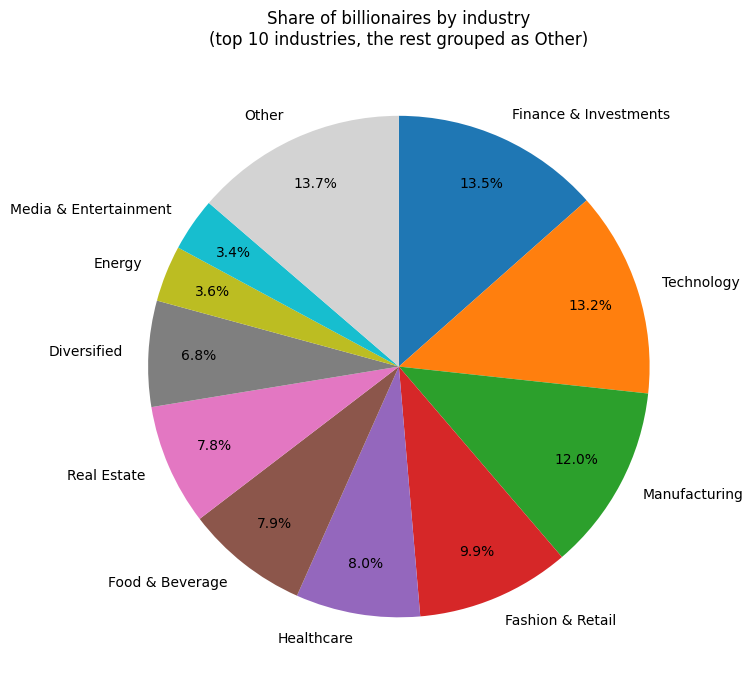

In [36]:
colors = list(plt.cm.tab10.colors) + ['lightgray']  

plt.figure(figsize=(10, 7))
plt.pie(
    final_counts.values,
    labels=final_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.8
)
plt.title('Share of billionaires by industry\n(top 10 industries, the rest grouped as Other)')
plt.tight_layout()
plt.show()